# Trial four: the parameters of the papers

Do our fish behave as the papers say when we use the parameters of Couzin et al. (2002) and Puckett et al. (2018)? The story and the definitions are in [chapter 4 of the README](../README.md#chapter-4-trial-four-paper-parameters).

- **Part A:** a ladder from our model (A0) to the Puckett model (A4), one change at a time.
- **Part B:** the Puckett model with 16, 32 and 64 fish and speeds from 0.2 to 5 BL/s.
- **Part C:** the Couzin diagram (changing the orientation zone), with Puckett's turn and with Couzin's slow turn, and the collective-memory test.

## Setup

In [1]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Find the checks folder (it contains study_code/) and let Python import the shared study code.
CHECKS_FOLDER = Path.cwd()
while not (CHECKS_FOLDER / "study_code" / "study_tools.py").is_file():
    if CHECKS_FOLDER == CHECKS_FOLDER.parent:
        raise FileNotFoundError("study_code/study_tools.py was not found in this folder or any parent folder.")
    CHECKS_FOLDER = CHECKS_FOLDER.parent
sys.path.insert(0, str(CHECKS_FOLDER / "study_code"))

import study_tools
from study_tools import (
    A0_SETTINGS, PUCKETT_SETTINGS, A0_COLOR, PUCKETT_COLOR, DIRECTION_NAMES,
    average, build_model, change_settings, final_label_counts, load_results,
    run_and_measure_last_third, run_many, short_table, summarize, translate,
)

# Where this trial keeps its saved results and its README figure.
DATA_FOLDER = CHECKS_FOLDER / "trial_four_paper_parameters" / "data"
FIGURE_FOLDER = CHECKS_FOLDER / "trial_four_paper_parameters" / "figures"
pd.set_option("display.precision", 3)
pd.set_option("display.width", 200)

## Settings

Every experiment setting of this trial. The first name of each ladder step is the name saved in the CSV file; it stays in Spanish because the saved results use it as a key.

In [2]:
SEEDS = list(range(10))

# Part A: each step adds one change to the previous one (saved name, English name, change).
LADDER_STEPS = [
    ("A0: nuestro modelo", "A0: our model", {}),
    ("A1: + visión 270°", "A1: + 270° vision", {"fov_degrees": 270.0}),
    ("A2: + giro máx. 1.75 rad", "A2: + turn limit 1.75 rad", {"turn_per_decision": 1.75}),
    ("A3: + ruido 0.01 rad", "A3: + noise 0.01 rad", {"noise_per_decision": 0.01}),
    ("A4: + arena 28 BL (Puckett)", "A4: + 28 BL arena (Puckett)", {"arena": 28.0}),
]

# Part B: group sizes of Puckett's experiments and the speed range that light will cause (BL/s).
GROUP_SIZES = [16, 32, 64]
SPEEDS = [0.2, 1.0, 2.6, 5.0]

# Part C: orientation radii (BL) for the Couzin diagram, with a fixed attraction radius.
ORIENTATION_RADII = [0.55, 0.75, 1.0, 1.5, 2.0, 3.0, 4.0, 5.0, 6.0, 7.0]
DIAGRAM_ATTRACTION_RADIUS = 7.0
COUZIN_TURN = 0.07   # rad per decision: 40 degrees per second x 0.1 s (Couzin et al. 2002)
# Where Couzin saw milling and a parallel group, in our units (his 1 unit = 0.5 BL).
COUZIN_TRANSITIONS = [(0.75, "Couzin: milling"), (1.25, "Couzin: parallel")]
ORDER_LINE = study_tools.ORDER_THRESHOLD   # 0.65: ordered from here on

# Part C, memory: in one long run, r_o goes up and then down (Couzin et al. 2002, Fig. 4).
MEMORY_RADII = [0.55, 0.65, 0.75, 0.875, 1.0, 1.125, 1.25, 1.5, 1.75, 2.0, 2.25]
DECISIONS_PER_VALUE = 2000

The configurations, built from the settings above.

In [3]:
# Part A: the ladder. The last step must be exactly the Puckett configuration of study_tools.py.
ladder = []
LADDER_NAMES = {}
previous = A0_SETTINGS
for saved_name, english_name, changes in LADDER_STEPS:
    previous = change_settings(previous, saved_name, changes)
    ladder.append(previous)
    LADDER_NAMES[saved_name] = english_name
for key in PUCKETT_SETTINGS:
    if key not in ["label", "base"]:
        assert ladder[-1][key] == PUCKETT_SETTINGS[key], key

# Part B: every group size with every speed.
groups_and_speeds = []
for n_fish in GROUP_SIZES:
    for speed in SPEEDS:
        label = f"N={n_fish}, v={speed:g}"
        groups_and_speeds.append(change_settings(PUCKETT_SETTINGS, label, {"n_fish": n_fish, "speed": speed}))

# Part C: the Couzin diagram with Puckett's turn and with Couzin's slow turn.
couzin_diagram = []
slow_turn_diagram = []
SLOW_TURN_NAMES = {}
for orientation_radius in ORIENTATION_RADII:
    changes = {"orientation_radius": orientation_radius, "attraction_radius": DIAGRAM_ATTRACTION_RADIUS}
    couzin_diagram.append(change_settings(PUCKETT_SETTINGS, f"r_o={orientation_radius:g}", changes))
    slow_changes = dict(changes)
    slow_changes["turn_per_decision"] = COUZIN_TURN
    slow_label = f"giro lento, r_o={orientation_radius:g}"
    slow_turn_diagram.append(change_settings(PUCKETT_SETTINGS, slow_label, slow_changes))
    SLOW_TURN_NAMES[slow_label] = f"slow turn, r_o={orientation_radius:g}"

# Part C, memory: start at the smallest r_o, with Puckett's turn or Couzin's slow turn.
memory_start = {"orientation_radius": MEMORY_RADII[0], "attraction_radius": DIAGRAM_ATTRACTION_RADIUS}
fast_turn_memory = change_settings(PUCKETT_SETTINGS, "memory, Puckett turn", memory_start)
slow_turn_memory = change_settings(fast_turn_memory, "memory, Couzin turn", {"turn_per_decision": COUZIN_TURN})

## Run or load

Each part loads its CSV file from `data/` if it exists; set `study_tools.RERUN = True` to simulate again.

In [4]:
ladder_results = run_many(ladder, SEEDS, DATA_FOLDER / "part_a_ladder.csv")
groups_results = run_many(groups_and_speeds, SEEDS, DATA_FOLDER / "part_b_groups_speeds.csv")
couzin_results = run_many(couzin_diagram, SEEDS, DATA_FOLDER / "part_c_couzin.csv")
slow_results = run_many(slow_turn_diagram, SEEDS, DATA_FOLDER / "part_c_couzin_slow_turn.csv")

Loaded saved results from part_a_ladder.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_b_groups_speeds.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_c_couzin.csv (set study_tools.RERUN = True to simulate again).
Loaded saved results from part_c_couzin_slow_turn.csv (set study_tools.RERUN = True to simulate again).


The memory test needs its own run function: one long simulation in which r_o changes.

In [5]:
def run_memory_experiment(settings, seed):
    """One long run: r_o goes up through MEMORY_RADII and then back down."""
    model = build_model(settings, seed)
    rows = []
    for direction, radii in [("subiendo", MEMORY_RADII), ("bajando", list(reversed(MEMORY_RADII)))]:
        for orientation_radius in radii:
            # The fish read this value at every decision, so changing it changes their behaviour.
            model.orientation_radius = orientation_radius
            moments = run_and_measure_last_third(model, DECISIONS_PER_VALUE)
            rows.append({
                "seed": seed, "direction": direction, "orientation_radius": orientation_radius,
                "polarization": average(moments, "polarization"),
                "rotation": average(moments, "rotation"),
                "largest_group_fraction": average(moments, "largest_fraction"),
            })
    return rows


def memory_results(settings, csv_path):
    """Run the memory test for all seeds, or load it if the CSV file exists."""
    if csv_path.exists() and not study_tools.RERUN:
        print("Loaded saved results from", csv_path.name)
    else:
        rows = []
        for seed in SEEDS:
            rows.extend(run_memory_experiment(settings, seed))
        pd.DataFrame(rows).to_csv(csv_path, index=False)
    return load_results(csv_path)


fast_memory = memory_results(fast_turn_memory, DATA_FOLDER / "part_c_memory.csv")
slow_memory = memory_results(slow_turn_memory, DATA_FOLDER / "part_c_memory_slow_turn.csv")

Loaded saved results from part_c_memory.csv
Loaded saved results from part_c_memory_slow_turn.csv


## Results tables

Mean ± standard error over the 10 seeds. *works* = in how many seeds the school works; *NND* = distance to the nearest neighbour.

**Part A, the ladder.**

In [6]:
ladder_summary = summarize(ladder_results, "label")
ladder_summary["name"] = translate(ladder_summary["label"], LADDER_NAMES)
short_table(ladder_summary, "name")

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,A0: our model,10/10,0.95 ± 0.00,0.03 ± 0.00,0.57 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.28 ± 0.00
1,A1: + 270° vision,10/10,0.97 ± 0.00,0.02 ± 0.00,0.59 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.29 ± 0.01
2,A2: + turn limit 1.75 rad,10/10,0.96 ± 0.01,0.04 ± 0.01,0.62 ± 0.04,0.99 ± 0.01,0.00 ± 0.00,0.26 ± 0.01
3,A3: + noise 0.01 rad,9/10,0.96 ± 0.01,0.04 ± 0.01,0.60 ± 0.02,0.99 ± 0.01,0.00 ± 0.00,0.27 ± 0.01
4,A4: + 28 BL arena (Puckett),6/10,0.89 ± 0.04,0.14 ± 0.06,0.60 ± 0.01,0.75 ± 0.11,0.00 ± 0.00,0.27 ± 0.01


How each seed of the ladder ends (labels from the means of the last third):

In [7]:
ladder_results["name"] = translate(ladder_results["label"], LADDER_NAMES)
final_label_counts(ladder_results, "name")

label_final,polarized,milling,swarm,fragmented
name,,,,
A0: our model,10,0,0,0
A1: + 270° vision,10,0,0,0
A2: + turn limit 1.75 rad,10,0,0,0
A3: + noise 0.01 rad,9,0,0,1
A4: + 28 BL arena (Puckett),6,0,0,4


**Part B, group sizes and speeds.** The step length is speed × 0.125 s.

In [8]:
groups_summary = summarize(groups_results, ["label", "n_fish", "speed", "step_length"])
table_b = short_table(groups_summary)
table_b.insert(1, "step length (BL)", groups_summary["step_length"])
table_b

,configuration,step length (BL),works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"N=16, v=0.2",0.025,6/10,0.91 ± 0.04,0.13 ± 0.07,0.59 ± 0.04,0.81 ± 0.10,0.00 ± 0.00,0.47 ± 0.00
1,"N=16, v=1",0.125,8/10,0.91 ± 0.06,0.13 ± 0.08,0.67 ± 0.08,0.84 ± 0.11,0.00 ± 0.00,0.30 ± 0.01
2,"N=16, v=2.6",0.325,3/10,0.87 ± 0.06,0.15 ± 0.07,0.72 ± 0.03,0.78 ± 0.12,0.05 ± 0.00,0.07 ± 0.01
3,"N=16, v=5",0.625,0/10,0.73 ± 0.03,0.28 ± 0.06,1.11 ± 0.13,0.43 ± 0.13,0.16 ± 0.02,0.04 ± 0.00
4,"N=32, v=0.2",0.025,8/10,0.92 ± 0.05,0.12 ± 0.07,0.56 ± 0.04,0.88 ± 0.10,0.00 ± 0.00,0.45 ± 0.00
5,"N=32, v=1",0.125,8/10,0.85 ± 0.01,0.08 ± 0.02,0.57 ± 0.02,0.94 ± 0.04,0.00 ± 0.00,0.23 ± 0.01
6,"N=32, v=2.6",0.325,0/10,0.53 ± 0.02,0.15 ± 0.04,0.67 ± 0.06,0.81 ± 0.11,0.75 ± 0.08,0.01 ± 0.00
7,"N=32, v=5",0.625,0/10,0.32 ± 0.01,0.10 ± 0.01,0.95 ± 0.10,0.50 ± 0.12,0.91 ± 0.02,0.01 ± 0.00
8,"N=64, v=0.2",0.025,0/10,0.13 ± 0.00,0.06 ± 0.00,0.49 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.40 ± 0.00
9,"N=64, v=1",0.125,0/10,0.11 ± 0.00,0.05 ± 0.00,0.42 ± 0.00,1.00 ± 0.00,0.39 ± 0.01,0.03 ± 0.00


**Part C, the Couzin diagram** (Puckett's turn). With r_a = 7 BL, *together* uses a 7 BL link; the last column repeats it with the fixed 5.5 BL link of the other parts.

In [9]:
couzin_summary = summarize(couzin_results, ["label", "orientation_radius"])
table_c = short_table(couzin_summary)
table_c["together (5.5 BL link)"] = study_tools.mean_and_error_text(couzin_summary, "together_fraction_fixed_link")
table_c

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL),together (5.5 BL link)
0,r_o=0.55,0/10,0.18 ± 0.01,0.11 ± 0.01,1.20 ± 0.12,0.44 ± 0.11,0.05 ± 0.01,0.14 ± 0.02,0.39 ± 0.11
1,r_o=0.75,0/10,0.17 ± 0.01,0.11 ± 0.01,1.13 ± 0.07,0.66 ± 0.11,0.06 ± 0.01,0.13 ± 0.01,0.62 ± 0.11
2,r_o=1,0/10,0.21 ± 0.02,0.13 ± 0.02,1.06 ± 0.11,0.58 ± 0.14,0.05 ± 0.01,0.16 ± 0.01,0.55 ± 0.14
3,r_o=1.5,0/10,0.22 ± 0.02,0.11 ± 0.01,0.84 ± 0.11,0.85 ± 0.06,0.05 ± 0.00,0.11 ± 0.02,0.81 ± 0.07
4,r_o=2,3/10,0.57 ± 0.03,0.11 ± 0.02,0.62 ± 0.06,0.99 ± 0.01,0.01 ± 0.00,0.22 ± 0.01,0.98 ± 0.02
5,r_o=3,10/10,0.98 ± 0.00,0.02 ± 0.00,0.58 ± 0.00,1.00 ± 0.00,0.00 ± 0.00,0.30 ± 0.01,1.00 ± 0.00
6,r_o=4,6/10,0.93 ± 0.02,0.16 ± 0.07,0.63 ± 0.03,0.80 ± 0.11,0.00 ± 0.00,0.27 ± 0.01,0.80 ± 0.11
7,r_o=5,9/10,0.93 ± 0.06,0.11 ± 0.08,0.64 ± 0.03,0.90 ± 0.10,0.00 ± 0.00,0.30 ± 0.01,0.90 ± 0.10
8,r_o=6,10/10,0.99 ± 0.00,0.05 ± 0.01,0.66 ± 0.01,1.00 ± 0.00,0.00 ± 0.00,0.33 ± 0.01,1.00 ± 0.00
9,r_o=7,10/10,0.99 ± 0.00,0.06 ± 0.01,0.74 ± 0.04,1.00 ± 0.00,0.00 ± 0.00,0.31 ± 0.01,1.00 ± 0.00


In [10]:
final_label_counts(couzin_results)

label_final,polarized,milling,swarm,fragmented
label,,,,
r_o=0.55,0,0,2,8
r_o=0.75,0,0,4,6
r_o=1,0,0,4,6
r_o=1.5,0,0,5,5
r_o=2,3,0,6,1
r_o=3,10,0,0,0
r_o=4,6,0,0,4
r_o=5,9,0,0,1
r_o=6,10,0,0,0


**Part C with Couzin's slow turn** (0.07 rad per decision).

In [11]:
slow_summary = summarize(slow_results, ["label", "orientation_radius"])
slow_summary["name"] = translate(slow_summary["label"], SLOW_TURN_NAMES)
short_table(slow_summary, "name")

,configuration,works,polarization,rotation,NND (BL),time together,time with collision,closest pair (BL)
0,"slow turn, r_o=0.55",0/10,0.19 ± 0.01,0.20 ± 0.03,1.07 ± 0.04,0.61 ± 0.16,0.38 ± 0.02,0.01 ± 0.00
1,"slow turn, r_o=0.75",0/10,0.17 ± 0.01,0.21 ± 0.04,1.17 ± 0.07,0.72 ± 0.14,0.34 ± 0.04,0.01 ± 0.00
2,"slow turn, r_o=1",0/10,0.21 ± 0.02,0.30 ± 0.05,1.11 ± 0.09,0.70 ± 0.15,0.34 ± 0.03,0.02 ± 0.00
3,"slow turn, r_o=1.5",0/10,0.30 ± 0.07,0.48 ± 0.07,1.12 ± 0.10,0.90 ± 0.10,0.37 ± 0.04,0.02 ± 0.00
4,"slow turn, r_o=2",0/10,0.65 ± 0.09,0.31 ± 0.09,0.67 ± 0.06,0.89 ± 0.08,0.27 ± 0.03,0.02 ± 0.00
5,"slow turn, r_o=3",0/10,0.88 ± 0.06,0.18 ± 0.09,0.56 ± 0.01,0.80 ± 0.13,0.15 ± 0.01,0.02 ± 0.00
6,"slow turn, r_o=4",0/10,0.97 ± 0.00,0.05 ± 0.01,0.61 ± 0.01,1.00 ± 0.00,0.12 ± 0.01,0.03 ± 0.00
7,"slow turn, r_o=5",0/10,0.96 ± 0.01,0.06 ± 0.01,0.65 ± 0.01,0.99 ± 0.01,0.12 ± 0.01,0.03 ± 0.00
8,"slow turn, r_o=6",0/10,0.97 ± 0.01,0.05 ± 0.01,0.66 ± 0.01,1.00 ± 0.00,0.11 ± 0.01,0.03 ± 0.01
9,"slow turn, r_o=7",2/10,0.95 ± 0.01,0.07 ± 0.01,0.74 ± 0.02,1.00 ± 0.00,0.09 ± 0.01,0.03 ± 0.01


In [12]:
slow_results["name"] = translate(slow_results["label"], SLOW_TURN_NAMES)
final_label_counts(slow_results, "name")

label_final,polarized,milling,swarm,fragmented
name,,,,
"slow turn, r_o=0.55",0,0,6,4
"slow turn, r_o=0.75",0,0,6,4
"slow turn, r_o=1",0,0,7,3
"slow turn, r_o=1.5",1,3,5,1
"slow turn, r_o=2",5,2,1,2
"slow turn, r_o=3",8,0,0,2
"slow turn, r_o=4",10,0,0,0
"slow turn, r_o=5",10,0,0,0
"slow turn, r_o=6",10,0,0,0


**Part C, memory.** Mean over the 10 seeds while r_o goes up and while it goes down.

In [13]:
def memory_summary(memory):
    """Mean and standard error of every measurement, per direction and r_o."""
    table = memory.copy()
    table["direction"] = translate(table["direction"], DIRECTION_NAMES)
    return table.groupby(["direction", "orientation_radius"], sort=False)[
        ["polarization", "rotation", "largest_group_fraction"]].agg(["mean", "sem"])


fast_memory_summary = memory_summary(fast_memory)
slow_memory_summary = memory_summary(slow_memory)
slow_memory_summary

polarization        rotation        largest_group_fraction           
                                      mean    sem     mean    sem                   mean        sem
direction  orientation_radius                                                                      
going up   0.550                     0.182  0.009    0.222  0.024                  0.940  3.472e-02
           0.650                     0.202  0.012    0.342  0.041                  0.999  1.074e-03
           0.750                     0.176  0.007    0.312  0.041                  0.999  9.459e-04
           0.875                     0.178  0.006    0.329  0.054                  0.985  1.500e-02
           1.000                     0.217  0.012    0.408  0.039                  0.996  2.127e-03
           1.125                     0.191  0.009    0.511  0.026                  0.997  3.191e-03
           1.250                     0.202  0.011    0.553  0.036                  0.997  2.129e-03
           1.500                     0.223  0.009    0.665  0.024                  0.999  6.607e-04
           1.750                     0.248  0.040    0.683  0.042                  1.000  4.505e-05
           2.000                     0.286  0.072    0.674  0.069                  1.000  0.000e+00
           2.250                     0.375  0.096    0.600  0.093                  0.996  4.114e-03
going down 2.250                     0.382  0.097    0.617  0.097                  1.000  0.000e+00
           2.000                     0.344  0.096    0.618  0.088                  0.999  1.059e-03
           1.750                     0.356  0.093    0.596  0.082                  0.998  1.517e-03
           1.500                     0.207  0.014    0.626  0.017                  0.999  1.051e-03
           1.250                     0.215  0.013    0.495  0.033                  0.999  9.159e-04
           1.125                     0.198  0.010    0.420  0.046                  0.997  2.308e-03
           1.000                     0.199  0.011    0.396  0.036                  0.996  3.121e-03
           0.875                     0.198  0.009    0.337  0.040                  0.999  1.374e-03
           0.750                     0.189  0.011    0.311  0.041                  0.999  6.682e-04
           0.650                     0.196  0.009    0.265  0.033                  0.982  1.400e-02
           0.550                     0.177  0.007    0.298  0.035                  1.000  1.577e-04

## Figures

**The README figure: the Couzin diagram** with Puckett's turn. Dotted lines: where Couzin saw milling and a parallel group. Dashed line: the order threshold 0.65.

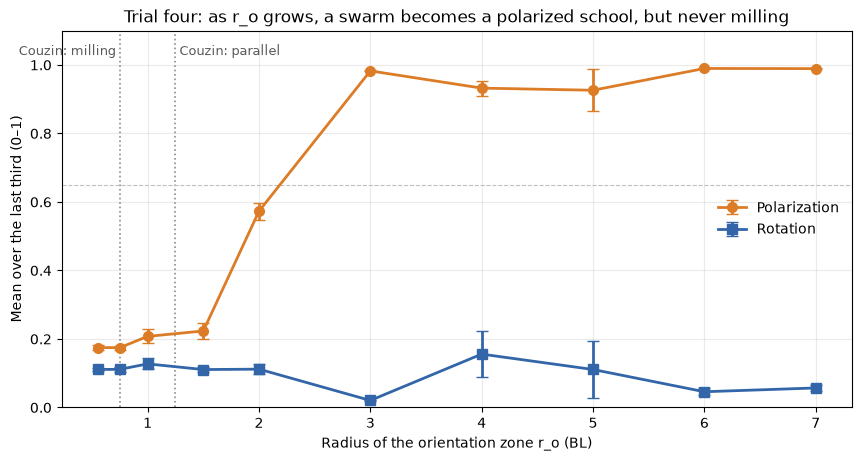

In [14]:
fig, axis = plt.subplots(figsize=(8.5, 4.5), constrained_layout=True)
axis.errorbar(couzin_summary["orientation_radius"], couzin_summary["polarization"],
              yerr=couzin_summary["polarization_se"], color=PUCKETT_COLOR, marker="o",
              markersize=7, linewidth=2, capsize=4, label="Polarization")
axis.errorbar(couzin_summary["orientation_radius"], couzin_summary["rotation"],
              yerr=couzin_summary["rotation_se"], color=A0_COLOR, marker="s",
              markersize=7, linewidth=2, capsize=4, label="Rotation")
# The two labels point away from each other, so they do not overlap.
for (radius, text), side in zip(COUZIN_TRANSITIONS, ["right", "left"]):
    axis.axvline(radius, color="0.55", linestyle=":", linewidth=1.2)
    axis.text(radius, 1.02, f" {text} ", ha=side, va="bottom", fontsize=9, color="0.35")
axis.axhline(ORDER_LINE, color="0.75", linestyle="--", linewidth=0.8)
axis.set_xlabel("Radius of the orientation zone r_o (BL)")
axis.set_ylabel("Mean over the last third (0–1)")
axis.set_ylim(0, 1.1)
axis.grid(alpha=0.25)
axis.legend(frameon=False, loc="center right")
axis.set_title("Trial four: as r_o grows, a swarm becomes a polarized school, but never milling")
fig.savefig(FIGURE_FOLDER / "part_c_couzin_diagram.png", dpi=150)
plt.show()

Part A: polarization, nearest-neighbour distance and time together on each step of the ladder.

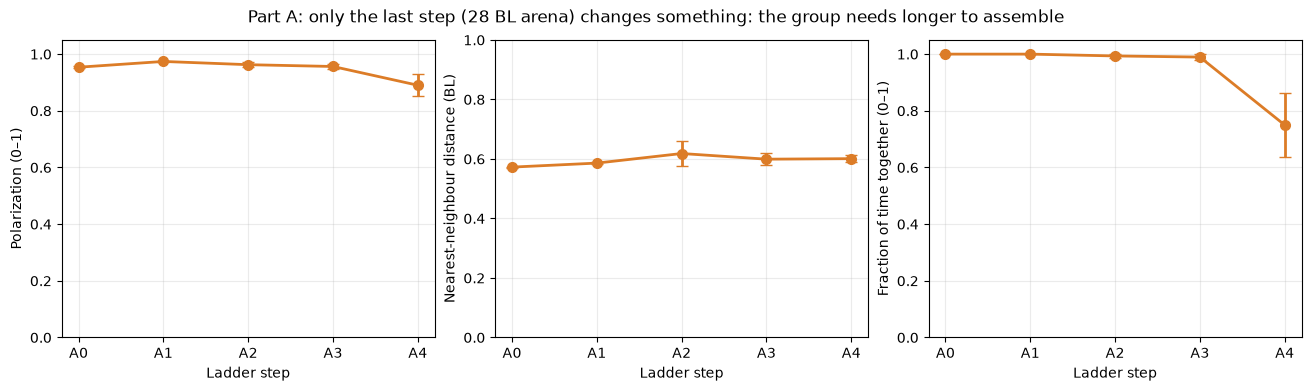

In [15]:
steps = list(range(len(ladder_summary)))
step_names = []
for label in ladder_summary["label"]:
    step_names.append(label[:2])   # "A0", "A1", ...
panels = [("polarization", "Polarization (0–1)", 1.05),
          ("nnd", "Nearest-neighbour distance (BL)", 1.0),
          ("together_fraction", "Fraction of time together (0–1)", 1.05)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), constrained_layout=True)
for axis, (column, axis_label, top) in zip(axes, panels):
    axis.errorbar(steps, ladder_summary[column], yerr=ladder_summary[column + "_se"],
                  color=PUCKETT_COLOR, marker="o", markersize=7, linewidth=2, capsize=4)
    axis.set_xticks(steps)
    axis.set_xticklabels(step_names)
    axis.set_xlabel("Ladder step")
    axis.set_ylabel(axis_label)
    axis.set_ylim(0, top)
    axis.grid(alpha=0.25)
fig.suptitle("Part A: only the last step (28 BL arena) changes something: the group needs longer to assemble")
plt.show()

Part B: one line per group size; the x axis shows the speed and the step length.

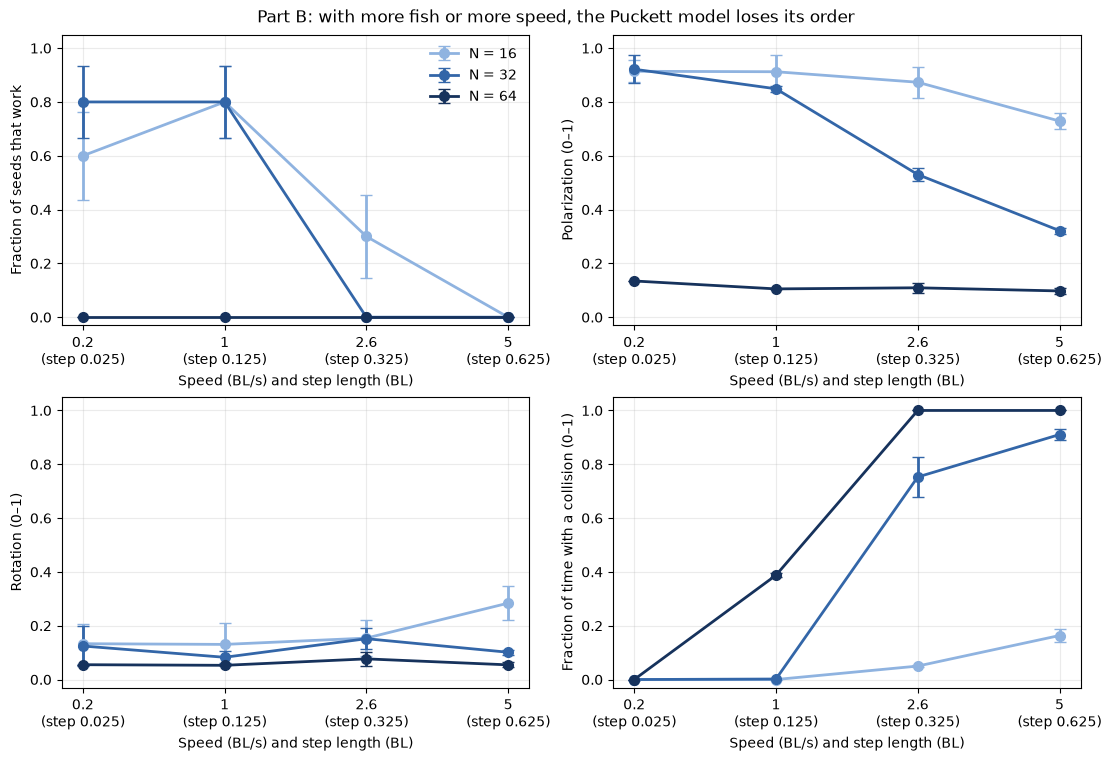

In [16]:
GROUP_COLORS = {16: "#8fb3e0", 32: "#3366a8", 64: "#16325c"}   # darker = bigger group
panels = [("works", "Fraction of seeds that work"), ("polarization", "Polarization (0–1)"),
          ("rotation", "Rotation (0–1)"), ("collision_fraction", "Fraction of time with a collision (0–1)")]
positions = list(range(len(SPEEDS)))   # the four speeds at equal distances
tick_texts = []
for speed in SPEEDS:
    tick_texts.append(f"{speed:g}\n(step {speed * PUCKETT_SETTINGS['dt']:g})")

fig, axes = plt.subplots(2, 2, figsize=(11, 7.5), constrained_layout=True)
for axis, (column, axis_label) in zip(axes.flat, panels):
    for n_fish in GROUP_SIZES:
        rows = groups_summary[groups_summary["n_fish"] == n_fish]
        axis.errorbar(positions, rows[column], yerr=rows[column + "_se"], color=GROUP_COLORS[n_fish],
                      marker="o", markersize=7, linewidth=2, capsize=4, label=f"N = {n_fish}")
    axis.set_xticks(positions)
    axis.set_xticklabels(tick_texts)
    axis.set_xlabel("Speed (BL/s) and step length (BL)")
    axis.set_ylabel(axis_label)
    axis.set_ylim(-0.03, 1.05)
    axis.grid(alpha=0.25)
axes[0, 0].legend(frameon=False)
fig.suptitle("Part B: with more fish or more speed, the Puckett model loses its order")
plt.show()

Part C: the fraction of time the group spends in each state, for each r_o.

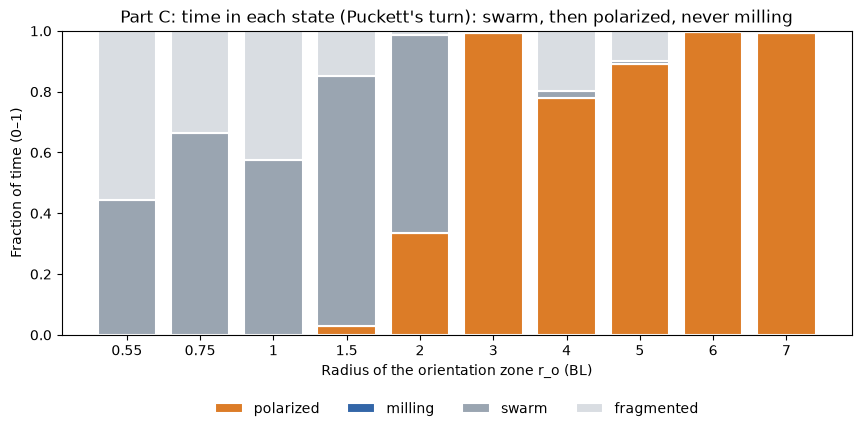

In [17]:
STATE_COLORS = {"polarized": PUCKETT_COLOR, "milling": A0_COLOR, "swarm": "#9aa5b1", "fragmented": "#d9dde2"}
positions = list(range(len(couzin_summary)))
radius_texts = []
for radius in couzin_summary["orientation_radius"]:
    radius_texts.append(f"{radius:g}")

bottom = np.zeros(len(couzin_summary))
fig, axis = plt.subplots(figsize=(8.5, 4.2), constrained_layout=True)
for state in STATE_COLORS:
    values = couzin_summary["time_" + state].to_numpy()
    axis.bar(positions, values, bottom=bottom, color=STATE_COLORS[state], edgecolor="white",
             linewidth=1.5, label=state)
    bottom = bottom + values
axis.set_xticks(positions)
axis.set_xticklabels(radius_texts)
axis.set_xlabel("Radius of the orientation zone r_o (BL)")
axis.set_ylabel("Fraction of time (0–1)")
axis.legend(frameon=False, ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.18))
axis.set_title("Part C: time in each state (Puckett's turn): swarm, then polarized, never milling")
plt.show()

Part C: Puckett's fast turn against Couzin's slow turn.

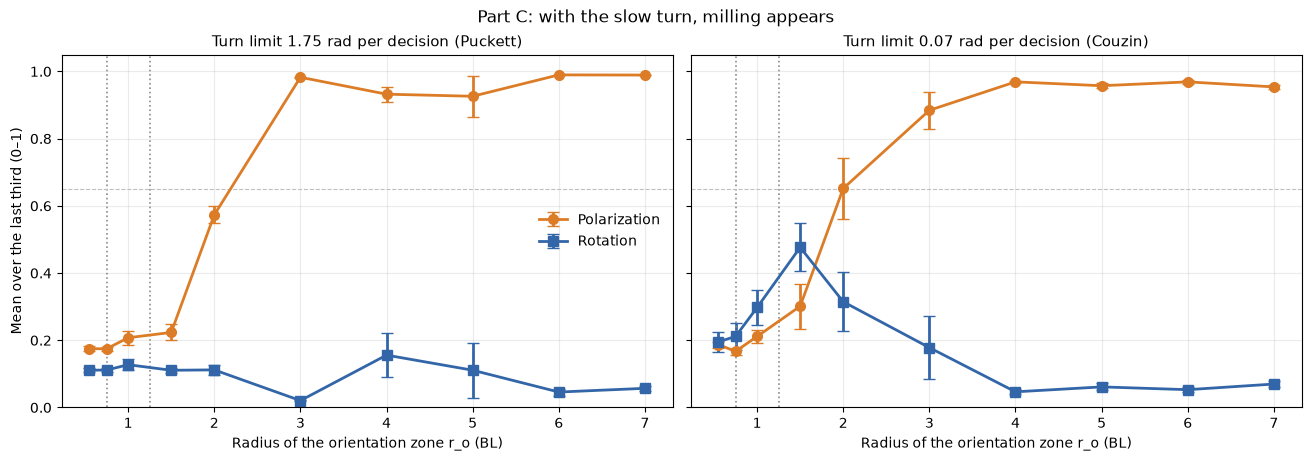

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True, constrained_layout=True)
for axis, summary, title in [(axes[0], couzin_summary, "Turn limit 1.75 rad per decision (Puckett)"),
                             (axes[1], slow_summary, "Turn limit 0.07 rad per decision (Couzin)")]:
    axis.errorbar(summary["orientation_radius"], summary["polarization"], yerr=summary["polarization_se"],
                  color=PUCKETT_COLOR, marker="o", markersize=7, linewidth=2, capsize=4, label="Polarization")
    axis.errorbar(summary["orientation_radius"], summary["rotation"], yerr=summary["rotation_se"],
                  color=A0_COLOR, marker="s", markersize=7, linewidth=2, capsize=4, label="Rotation")
    for radius, text in COUZIN_TRANSITIONS:
        axis.axvline(radius, color="0.55", linestyle=":", linewidth=1.2)
    axis.axhline(ORDER_LINE, color="0.75", linestyle="--", linewidth=0.8)
    axis.set_xlabel("Radius of the orientation zone r_o (BL)")
    axis.set_title(title, fontsize=11)
    axis.set_ylim(0, 1.05)
    axis.grid(alpha=0.25)
axes[0].set_ylabel("Mean over the last third (0–1)")
axes[0].legend(frameon=False, loc="center right")
fig.suptitle("Part C: with the slow turn, milling appears")
plt.show()

Part C, memory: solid line = r_o going up, dashed line = r_o going down (mean ± standard error).

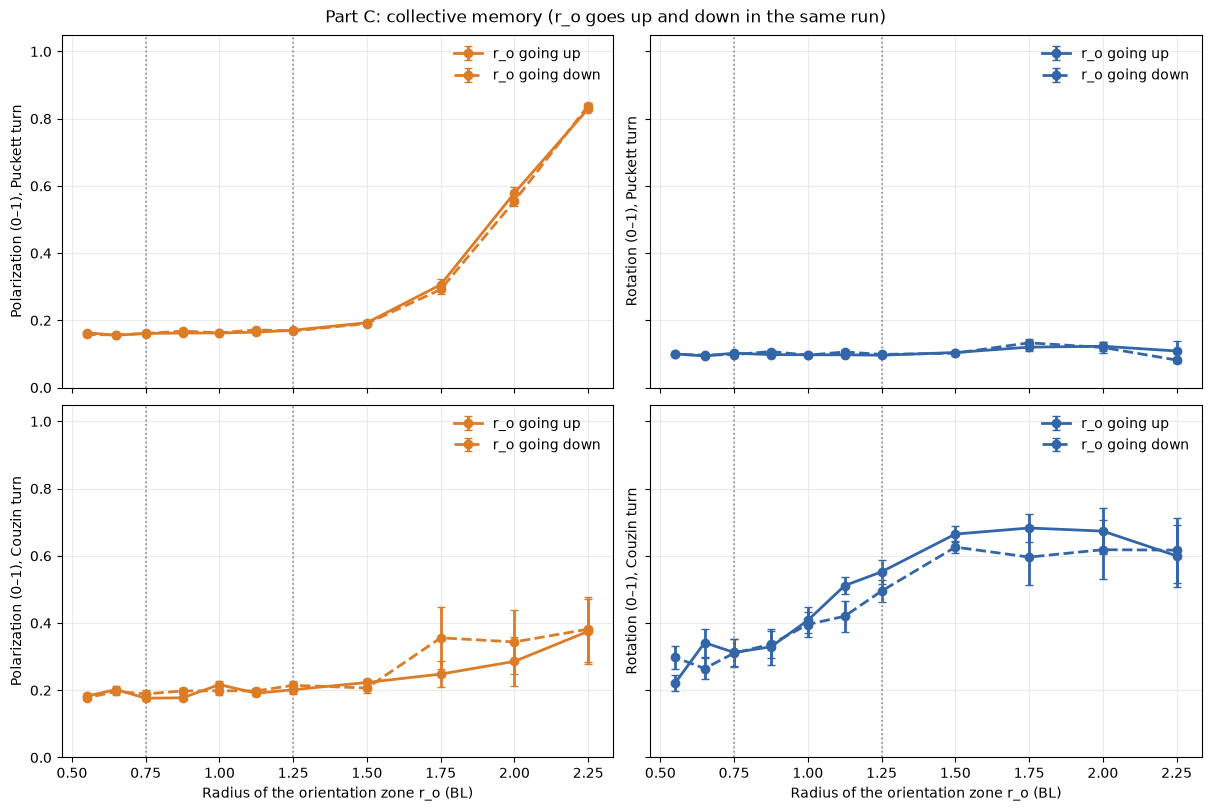

In [19]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharex=True, sharey=True, constrained_layout=True)
for row_index, (summary, turn_name) in enumerate([(fast_memory_summary, "Puckett turn"),
                                                   (slow_memory_summary, "Couzin turn")]):
    for column_index, (column, axis_label, color) in enumerate([("polarization", "Polarization", PUCKETT_COLOR),
                                                                  ("rotation", "Rotation", A0_COLOR)]):
        axis = axes[row_index, column_index]
        for direction, line_style in [("going up", "-"), ("going down", "--")]:
            rows = summary.loc[direction]
            axis.errorbar(rows.index, rows[(column, "mean")], yerr=rows[(column, "sem")], color=color,
                          linestyle=line_style, marker="o", markersize=6, linewidth=2, capsize=3,
                          label=f"r_o {direction}")
        for radius, text in COUZIN_TRANSITIONS:
            axis.axvline(radius, color="0.55", linestyle=":", linewidth=1.2)
        axis.set_ylabel(f"{axis_label} (0–1), {turn_name}")
        axis.set_ylim(0, 1.05)
        axis.grid(alpha=0.25)
        axis.legend(frameon=False)
axes[1, 0].set_xlabel("Radius of the orientation zone r_o (BL)")
axes[1, 1].set_xlabel("Radius of the orientation zone r_o (BL)")
fig.suptitle("Part C: collective memory (r_o goes up and down in the same run)")
plt.show()

## Conclusion

- **Ladder:** A0, A1 and A2 work in 10 of 10 seeds, A3 in 9 and A4 in 6. Only the last step matters: in the 28 BL arena the fish need longer to find each other, so some groups are still assembling.
- **Group size and speed:** with 16 or 32 fish at up to 1 BL/s the school works in 6 to 8 of 10 seeds; at 2.6 and 5 BL/s it works in at most 3 of 10 seeds, with collisions; 64 fish are always a swarm.
- **Couzin diagram:** a swarm for small r_o and a polarized school from r_o = 3 BL, but **no milling** with Puckett's turn. With Couzin's slow turn, milling appears (with many collisions), and it stays when r_o goes up and down again.